# Member 2 — Clustering Track: K-Means (Gas Sensor Array Drift)

**Review 2 scope (Member 2):** the **K-Means** half of clustering deliverable **B1** — fit the model and obtain
cluster labels with no errors. Agglomerative clustering is in `member3_agglomerative_clustering.ipynb`.

- Dataset: UCI *Gas Sensor Array Drift at Different Concentrations* — 13,910 measurements, 128 features
  (16 sensors x 8 features), 6 gases, recorded over 36 months in 10 batches.
- The gas label (`class`) and `concentration` are **removed before fitting**; clustering never sees them. They are
  used only at the end to describe what the clusters contain.
- Preprocessing and k are the same as in `member1_clustering_evaluation.ipynb` (B2 metrics, B3 plots), so both
  notebooks describe the same K-Means clusters. The labels are saved to `results/clustering/kmeans_labels.csv`.

In [1]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from pathlib import Path
from IPython.display import display

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
sns.set_theme(style='whitegrid', palette='colorblind')
warnings.filterwarnings('ignore', category=UserWarning)
os.environ['PYTHONWARNINGS'] = 'ignore::UserWarning'

DATA_PATH = Path('../data/raw/gassensor/gas_sensor/gas_sensor.csv')
RESULTS_DIR = Path('../results/clustering')
MODELS_DIR = Path('../models/clustering')
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
MODELS_DIR.mkdir(parents=True, exist_ok=True)

def save_fig(name):
    plt.tight_layout()
    plt.savefig(RESULTS_DIR / name, dpi=150, bbox_inches='tight')

## 1. Load and audit

The ten raw `batch*.dat` files (LibSVM format, `class;concentration feature:value ...`) were converted once into a
single CSV by `data/raw/gassensor/convert_gas_sensor.py`; the notebook reads that CSV through a relative path so it
runs on any machine.

In [2]:
df = pd.read_csv(DATA_PATH)
GAS_NAMES = {1: 'Ethanol', 2: 'Ethylene', 3: 'Ammonia', 4: 'Acetaldehyde', 5: 'Acetone', 6: 'Toluene'}

y_gas = df['class'].map(GAS_NAMES)                    # kept aside; never used for fitting
X_raw = df.drop(columns=['class', 'concentration'])

print('shape:', df.shape, '| clustering features:', X_raw.shape[1])
print('missing values:', int(X_raw.isna().sum().sum()), '| infinite values:', int(np.isinf(X_raw.values).sum()),
      '| duplicate rows:', int(df.duplicated().sum()))
print('feature value range: %.1f to %.1f' % (X_raw.values.min(), X_raw.values.max()))
skew = X_raw.skew().abs()
print('median |skewness|: %.1f | features with |skewness| > 5: %d' % (skew.median(), (skew > 5).sum()))
display(y_gas.value_counts().rename('measurements').to_frame())

shape: (13910, 130) | clustering features: 128
missing values: 0 | infinite values: 0 | duplicate rows: 0
feature value range: -23660.6 to 670687.3
median |skewness|: 2.4 | features with |skewness| > 5: 36


,measurements
class,
Acetone,3009
Ethylene,2926
Ethanol,2565
Acetaldehyde,1936
Toluene,1833
Ammonia,1641


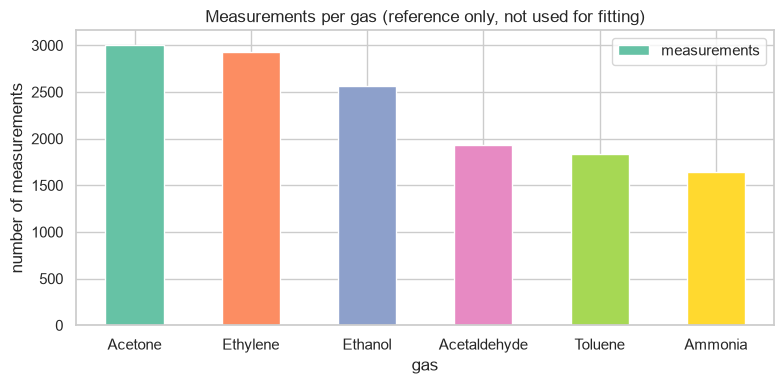

In [3]:
fig, ax = plt.subplots(figsize=(8, 4))
y_gas.value_counts().plot.bar(ax=ax, color=sns.color_palette('Set2'), label='measurements')
ax.set_title('Measurements per gas (reference only, not used for fitting)')
ax.set_xlabel('gas')
ax.set_ylabel('number of measurements')
ax.legend()
plt.xticks(rotation=0)
save_fig('m2_gas_distribution.png')
plt.show()

**Audit findings.** No missing, infinite or duplicate values, so **no imputation is needed** (an imputer would do
nothing here). The real problem is scale and skew: values range from large negatives to hundreds of thousands, and many
features are heavily skewed. That drives the preprocessing below.

## 2. Preprocessing

1. **Signed log transform** `sign(x) * log1p(|x|)` — compresses the long tails while keeping the sign of the many
   negative features (a plain log would fail on them).
2. **`StandardScaler`** — mean 0, std 1 per feature. K-Means uses Euclidean distance, so without scaling the
   resistance features (~10^4) would decide every cluster alone.

Clustering has no train/test split, so the scaler is fitted on the full feature matrix; no label information is used.

In [4]:
X_log = np.sign(X_raw) * np.log1p(X_raw.abs())
scaler = StandardScaler().fit(X_log)
X = scaler.transform(X_log)
print('scaled matrix:', X.shape)
print('max |skewness| before: %.1f | after signed log: %.1f' % (X_raw.skew().abs().max(), X_log.skew().abs().max()))

scaled matrix: (13910, 128)
max |skewness| before: 117.9 | after signed log: 6.2


## 3. Choosing k (without the labels)

The data has 6 gases, but using that to set k would let the labels steer the fit. k is chosen from the data alone
with the **elbow** of the K-Means inertia curve, located with the max-distance-to-chord rule. The full elbow,
silhouette and dendrogram analysis is in the B2 notebook; it gives the same k.

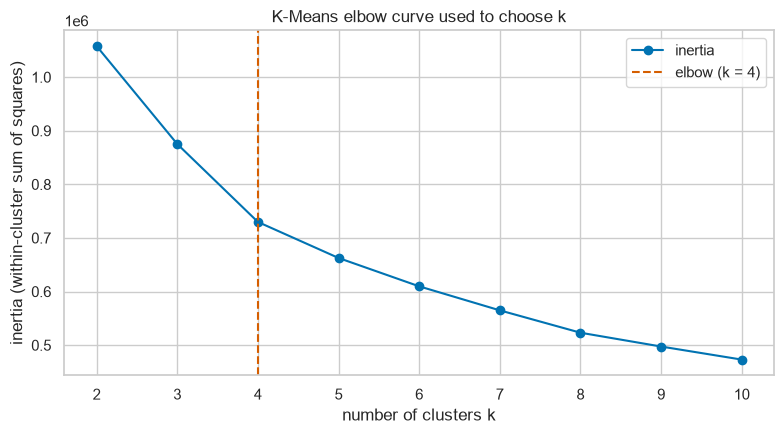

chosen k = 4


In [5]:
k_values = list(range(2, 11))
inertia = [KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(X).inertia_ for k in k_values]

def elbow_point(x, y):
    """Index of the point furthest from the chord joining the first and last points."""
    x, y = np.asarray(x, float), np.asarray(y, float)
    xn, yn = (x - x[0]) / (x[-1] - x[0]), (y - y[-1]) / (y[0] - y[-1])
    return int(np.argmax(np.abs(yn - (1 - xn))))

K = k_values[elbow_point(k_values, inertia)]

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(k_values, inertia, marker='o', label='inertia')
ax.axvline(K, color='C3', ls='--', label=f'elbow (k = {K})')
ax.set_title('K-Means elbow curve used to choose k')
ax.set_xlabel('number of clusters k')
ax.set_ylabel('inertia (within-cluster sum of squares)')
ax.legend()
save_fig('m2_elbow_choose_k.png')
plt.show()
print('chosen k =', K)

**Observation.** Inertia falls steeply up to k = 4 and then in small, even steps, so the elbow is at **k = 4**.
This is lower than the 6 gases, which is acceptable: clustering finds the groups the *sensor data* supports, and the
B2 notebook shows the Ward dendrogram also has its natural cut at 4 clusters.

## 4. K-Means

1. Initialise k centroids with **k-means++** (spread-out starting points).
2. Assign every measurement to its nearest centroid.
3. Move each centroid to the mean of its points.
4. Repeat until assignments stop changing. The objective is **inertia** (sum of squared distances to the centroid).

`n_init=10` runs the algorithm from 10 starts and keeps the best one, since K-Means can get stuck in a local minimum.

In [6]:
kmeans = KMeans(n_clusters=K, n_init=10, random_state=RANDOM_STATE).fit(X)
km_labels = kmeans.labels_
print('iterations to converge:', kmeans.n_iter_, '| final inertia: %.0f' % kmeans.inertia_)
print('cluster sizes:', np.bincount(km_labels).tolist())

iterations to converge: 15 | final inertia: 729790
cluster sizes: [4653, 3766, 2486, 3005]


### 4.1 Cluster profiles

Each sensor's first feature is its **steady-state resistance change** (features 1, 9, 17, ..., 121). The heatmap shows
the K-Means centroids on those 16 features (scaled units), i.e. how strongly each sensor reacts in each cluster.

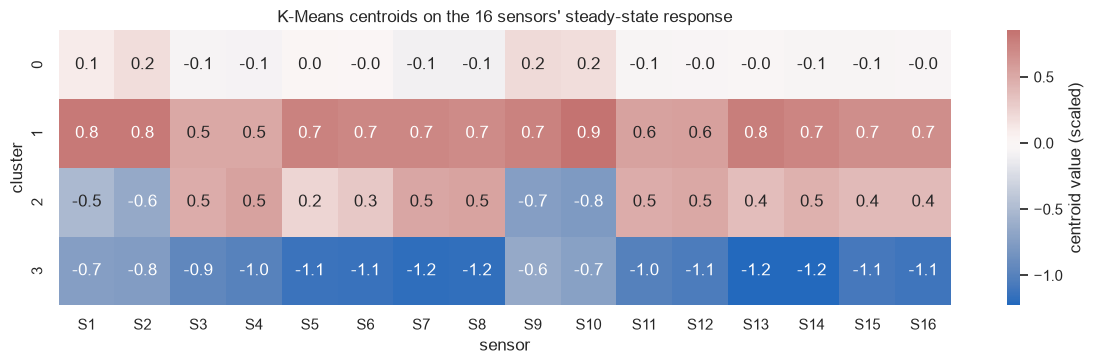

In [7]:
steady = [f'feature_{1 + 8 * s}' for s in range(16)]
idx = [X_raw.columns.get_loc(c) for c in steady]
profile = pd.DataFrame(kmeans.cluster_centers_[:, idx], columns=[f'S{s + 1}' for s in range(16)])
profile.index.name = 'cluster'

plt.figure(figsize=(12, 3.8))
sns.heatmap(profile, cmap='vlag', center=0, annot=True, fmt='.1f', cbar_kws={'label': 'centroid value (scaled)'})
plt.title('K-Means centroids on the 16 sensors\' steady-state response')
plt.xlabel('sensor')
plt.ylabel('cluster')
save_fig('m2_kmeans_centroid_profile.png')
plt.show()

**Observation.** The four clusters are separated mainly by **how strongly the sensors react**:
- cluster 1: every sensor responds well above average (+0.5 to +0.9);
- cluster 3: every sensor responds well below average (-0.6 to -1.2);
- cluster 2: a mixed pattern — sensors S1, S2, S9, S10 respond weakly (-0.5 to -0.8) while the rest respond above
  average. A sensor-specific pattern like this points to a specific gas (section 7 shows it is mostly Ethylene);
- cluster 0: close to the overall average on every sensor.

## 5. Cluster sizes and internal metrics

A quick sanity check that the fit is sensible and not degenerate (no tiny or giant clusters). The full metric
analysis (Silhouette, Davies-Bouldin, Calinski-Harabasz for both algorithms) is the B2 notebook's job.

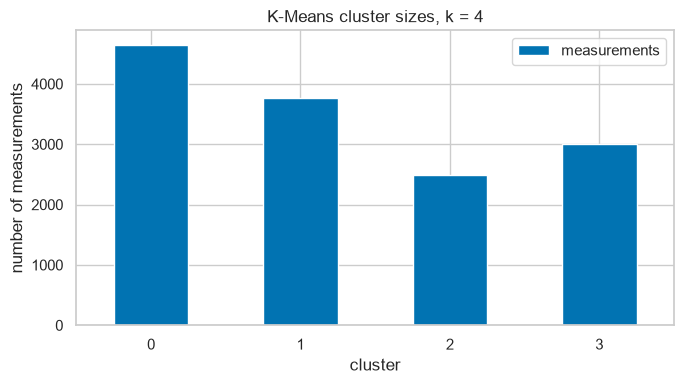

,K-Means
silhouette,0.267
davies_bouldin,1.253
calinski_harabasz,6673.565


In [8]:
sizes = pd.Series(km_labels).value_counts().sort_index()
ax = sizes.plot.bar(figsize=(7, 4), color=sns.color_palette('colorblind')[0], label='measurements')
ax.set_title(f'K-Means cluster sizes, k = {K}')
ax.set_xlabel('cluster')
ax.set_ylabel('number of measurements')
ax.legend()
plt.xticks(rotation=0)
save_fig('m2_cluster_sizes.png')
plt.show()

quick = pd.Series({'silhouette': silhouette_score(X, km_labels, random_state=RANDOM_STATE),
                   'davies_bouldin': davies_bouldin_score(X, km_labels),
                   'calinski_harabasz': calinski_harabasz_score(X, km_labels)}, name='K-Means')
display(quick.round(3).to_frame())

**Observation.** Cluster sizes are 4,653 / 3,766 / 2,486 / 3,005 — no cluster is tiny or dominant (largest 33%).
Silhouette 0.267, Davies-Bouldin 1.25 and Calinski-Harabasz 6,674: moderately separated clusters, identical to the
values in the B2 notebook because the preprocessing, k and `random_state` are the same.

## 6. What the clusters contain (labels used only now)

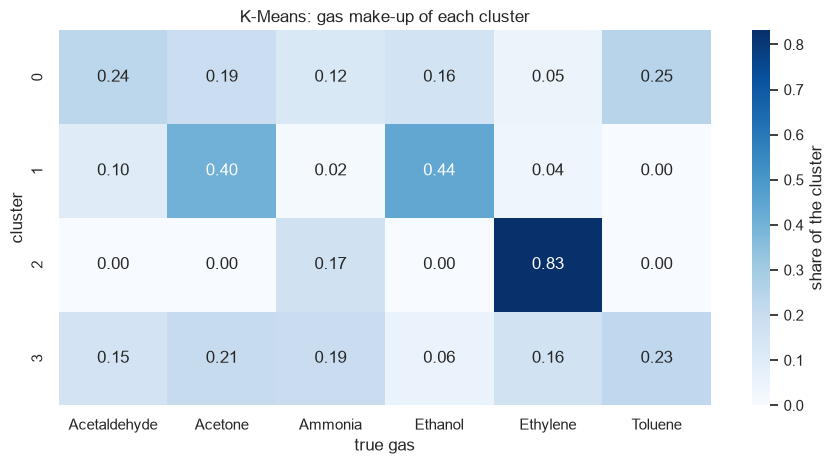

In [9]:
fig, ax = plt.subplots(figsize=(9, 4.8))
ct = pd.crosstab(pd.Series(km_labels, name='cluster'), y_gas.rename('gas'), normalize='index')
sns.heatmap(ct, annot=True, fmt='.2f', cmap='Blues', cbar_kws={'label': 'share of the cluster'}, ax=ax)
ax.set_title('K-Means: gas make-up of each cluster')
ax.set_xlabel('true gas')
ax.set_ylabel('cluster')
save_fig('m2_cluster_gas_makeup.png')
plt.show()

**Observation.**
- Cluster 2 is **83% Ethylene** — the mixed sensor pattern in section 4.1.
- Cluster 1 is **Acetone + Ethanol** (84%) — the strong-response group.
- Clusters 0 and 3 mix Acetaldehyde, Toluene, Ammonia and the rest. With 4 clusters for 6 gases, and sensor drift
  shifting each gas's response over the 36 months, a one-to-one match was not expected.

## 7. Save labels and model

In [10]:
out = pd.DataFrame({'kmeans_cluster': km_labels, 'gas': y_gas, 'concentration': df['concentration']})
out.to_csv(RESULTS_DIR / 'kmeans_labels.csv', index_label='row')

joblib.dump(kmeans, MODELS_DIR / 'kmeans.pkl')
joblib.dump(scaler, MODELS_DIR / 'clustering_scaler.pkl')
print('saved:', RESULTS_DIR / 'kmeans_labels.csv', '|', sorted(p.name for p in MODELS_DIR.glob('*.pkl')))
display(out.head())

saved: ../results/clustering/kmeans_labels.csv | ['clustering_scaler.pkl', 'kmeans.pkl']


,kmeans_cluster,gas,concentration
0,3,Ethanol,10.0
1,3,Ethanol,20.0
2,3,Ethanol,30.0
3,3,Ethanol,40.0
4,3,Ethanol,50.0


## 8. Summary

- **K-Means fitted with no errors:** `k=4`, `n_init=10`, k-means++ initialisation, converged in 15 iterations, on
  13,910 measurements x 128 signed-log, standardised features.
- k = 4 comes from the elbow curve, not from the gas labels; the labels were removed before fitting and used only in
  section 6.
- Clusters are separated by overall sensor response strength plus one sensor-specific pattern; they contain an
  Ethylene group and an Acetone + Ethanol group.
- Saved: `results/clustering/kmeans_labels.csv`, `models/clustering/kmeans.pkl`,
  `models/clustering/clustering_scaler.pkl`. Agglomerative clustering: Member 3's notebook. Metrics (B2) and
  PCA / t-SNE plots (B3): `member1_clustering_evaluation.ipynb`.